In [1]:
import xarray as xr
from datetime import datetime, date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = xr.load_dataset("target_variables/grib_files/t2m_40_45.grib", engine="cfgrib")
var_daily1 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_40_45.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
ds = xr.load_dataset("target_variables/grib_files/t2m_46_51.grib", engine="cfgrib")
var_daily2 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_46_51.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
ds = xr.load_dataset("target_variables/grib_files/t2m_52_57.grib", engine="cfgrib")
var_daily3 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_52_57.grib.5b7b6.idx' incompatible with GRIB file


In [5]:
ds = xr.load_dataset("target_variables/grib_files/t2m_58_63.grib", engine="cfgrib")
var_daily4 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_58_63.grib.5b7b6.idx' incompatible with GRIB file


In [6]:
ds = xr.load_dataset("target_variables/grib_files/t2m_64_69.grib", engine="cfgrib")
var_daily5 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_64_69.grib.5b7b6.idx' incompatible with GRIB file


In [7]:
ds = xr.load_dataset("target_variables/grib_files/t2m_70_75.grib", engine="cfgrib")
var_daily6 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_70_75.grib.5b7b6.idx' incompatible with GRIB file


In [8]:
ds = xr.load_dataset("target_variables/grib_files/t2m_76_81.grib", engine="cfgrib")
var_daily7 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_76_81.grib.5b7b6.idx' incompatible with GRIB file


In [9]:
ds = xr.load_dataset("target_variables/grib_files/t2m_82_87.grib", engine="cfgrib")
var_daily8 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_82_87.grib.5b7b6.idx' incompatible with GRIB file


In [10]:
ds = xr.load_dataset("target_variables/grib_files/t2m_88_93.grib", engine="cfgrib")
var_daily9 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_88_93.grib.5b7b6.idx' incompatible with GRIB file


In [11]:
ds = xr.load_dataset("target_variables/grib_files/t2m_94_99.grib", engine="cfgrib")
var_daily10 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_94_99.grib.5b7b6.idx' incompatible with GRIB file


In [12]:
ds = xr.load_dataset("target_variables/grib_files/t2m_00_05.grib", engine="cfgrib")
var_daily11 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_00_05.grib.5b7b6.idx' incompatible with GRIB file


In [13]:
ds = xr.load_dataset("target_variables/grib_files/t2m_06_10.grib", engine="cfgrib")
var_daily12 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_06_10.grib.5b7b6.idx' incompatible with GRIB file


In [14]:
ds = xr.load_dataset("target_variables/grib_files/t2m_11_15.grib", engine="cfgrib")
var_daily13 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_11_15.grib.5b7b6.idx' incompatible with GRIB file


In [15]:
ds = xr.load_dataset("target_variables/grib_files/t2m_16_20.grib", engine="cfgrib")
var_daily14 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_16_20.grib.5b7b6.idx' incompatible with GRIB file


In [16]:
ds = xr.load_dataset("target_variables/grib_files/t2m_21_25.grib", engine="cfgrib")
var_daily15 = ds.t2m.groupby(ds.t2m.time.dt.date).mean()

Ignoring index file 'target_variables/grib_files/t2m_21_25.grib.5b7b6.idx' incompatible with GRIB file


In [17]:
var_daily = xr.concat([var_daily1, var_daily2, var_daily3, var_daily4, var_daily5, var_daily6, var_daily7, var_daily8, var_daily9, var_daily10, 
                       var_daily11, var_daily12, var_daily13, var_daily14, var_daily15], dim='date')

In [18]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [19]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [20]:
var_daily = var_daily.reset_coords(['number', 'step', 'surface'], drop=True)
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=(month==12)|(month==1)|((month==2) & (day<29)))

In [21]:
var_daily = var_daily.sel(time=slice("1950-07", "2010-06"))

### Spatial weights

In [22]:
ds_oro = xr.load_dataset("target_variables/grib_files/orography_original_res.grib", engine="cfgrib")

Ignoring index file 'target_variables/grib_files/orography_original_res.grib.5b7b6.idx' incompatible with GRIB file


In [23]:
g = 9.80665

In [24]:
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

In [25]:
lat = ds_oro.latitude
land_frac = ds_oro.lsm + ds_oro.cl
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)

In [26]:
weights = np.cos(np.deg2rad(lat))*land_frac*mount_filt
weights.name = "weights"

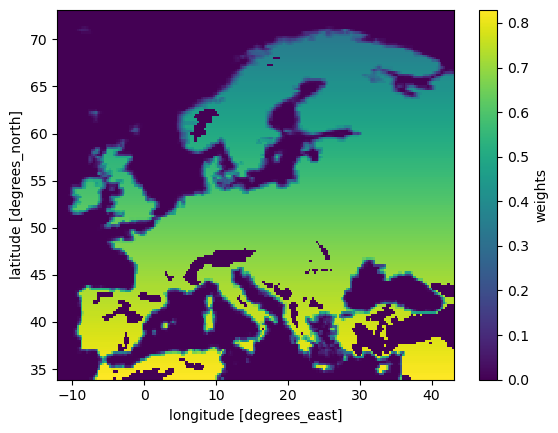

In [27]:
weights.plot()

In [28]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==12)&(day<4)) | ((month==2)&(day>25)) ))

In [29]:
var_7dMean_anom = var_7dMean.groupby('time.month') - var_7dMean.groupby('time.month').mean()

In [30]:
fit_params = var_7dMean_anom.polyfit('time', 1).polyfit_coefficients
var_7dMean_anom_detr = var_7dMean_anom - xr.polyval(var_7dMean_anom.time, fit_params)

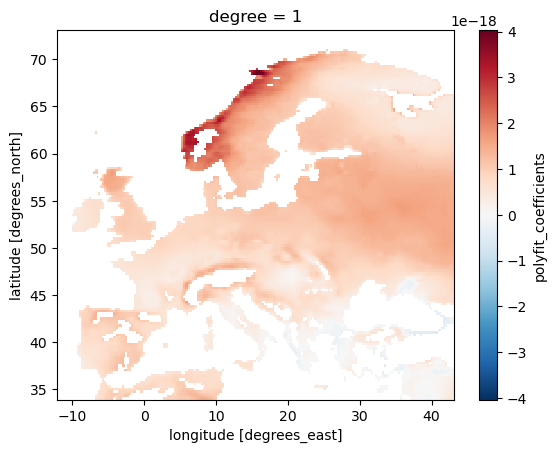

In [31]:
fit_params[0].where(land_frac*mount_filt>0.5).plot()

**Northern Europe**: 4°E-42°E, 59°N-72°N  
**Western-Central Europe**: 11°W-19°E, 47°N-59°N  
**Eastern Europe**: 19°E-42°E, 47°N-59°N  
**Southwestern Europe**: 10°W-10°E, 36°N-47°N  
**Southeastern Europe**: 10°E-30°E, 35°N-47°N

In [32]:
import cartopy.crs as ccrs

In [33]:
temp_map = var_daily.mean('time')

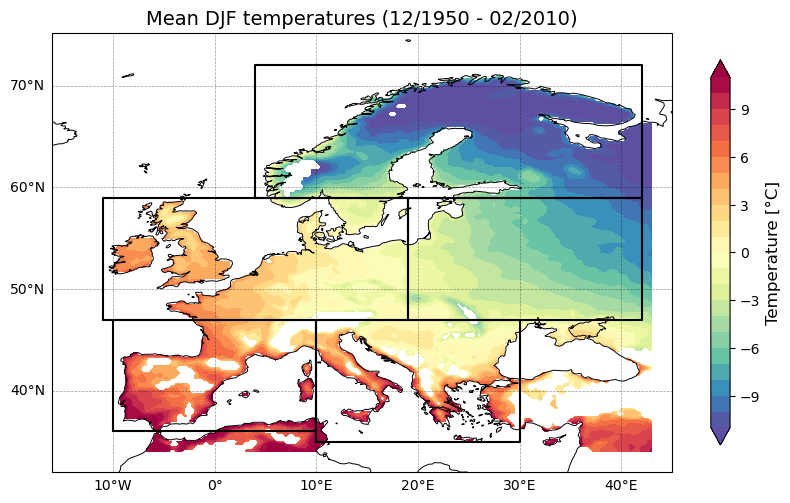

In [34]:
fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent((-16, 45, 32, 73))
ax.coastlines(resolution='50m', linewidth=0.7)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
gl.right_labels = False
gl.top_labels = False
contf = ax.contourf(temp_map.longitude, temp_map.latitude, temp_map.where(land_frac*mount_filt>0.5)-273.15, levels=np.linspace(-11,11,23), cmap="Spectral_r", extend="both")
ax.plot([4,42,42,4,4], [59,59,72,72,59], 'k')
ax.plot([-11,19,19,-11,-11], [47,47,59,59,47], 'k')
ax.plot([19,42,42,19,19], [47,47,59,59,47], 'k')
ax.plot([-10,10,10,-10,-10], [36,36,47,47,36], 'k')
ax.plot([10,30,30,10,10], [35,35,47,47,35], 'k')
cbar = fig.colorbar(contf, shrink=0.5)
cbar.set_label('Temperature [°C]',fontsize=12)
ax.set_title('Mean DJF temperatures (12/1950 - 02/2010)',fontsize=14)
plt.savefig('region_definition.pdf', bbox_inches='tight')

In [53]:
regmean_NE = var_7dMean_anom_detr.sel(longitude=slice(4,42), latitude=slice(72,59)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_WCE = var_7dMean_anom_detr.sel(longitude=slice(-11,19), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_EE = var_7dMean_anom_detr.sel(longitude=slice(19,42), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_SWE = var_7dMean_anom_detr.sel(longitude=slice(-10,10), latitude=slice(47,36)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_SEE = var_7dMean_anom_detr.sel(longitude=slice(10,30), latitude=slice(47,35)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [63]:
print(np.corrcoef([regmean_NE, regmean_WCE, regmean_EE, regmean_SWE, regmean_SEE]))

[[1.         0.38909346 0.52857033 0.01478377 0.04931423]
 [0.38909346 1.         0.64037881 0.57984437 0.52273792]
 [0.52857033 0.64037881 1.         0.29670195 0.63762039]
 [0.01478377 0.57984437 0.29670195 1.         0.48782289]
 [0.04931423 0.52273792 0.63762039 0.48782289 1.        ]]


In [67]:
NE_corr = xr.corr(var_7dMean_anom_detr, regmean_NE, dim='time')
WCE_corr = xr.corr(var_7dMean_anom_detr, regmean_WCE, dim='time')
EE_corr = xr.corr(var_7dMean_anom_detr, regmean_EE, dim='time')
SWE_corr = xr.corr(var_7dMean_anom_detr, regmean_SWE, dim='time')
SEE_corr = xr.corr(var_7dMean_anom_detr, regmean_SEE, dim='time')

In [70]:
weights2 = weights*(var_7dMean_anom_detr.var(dim='time'))
weights2.name = "weights2"

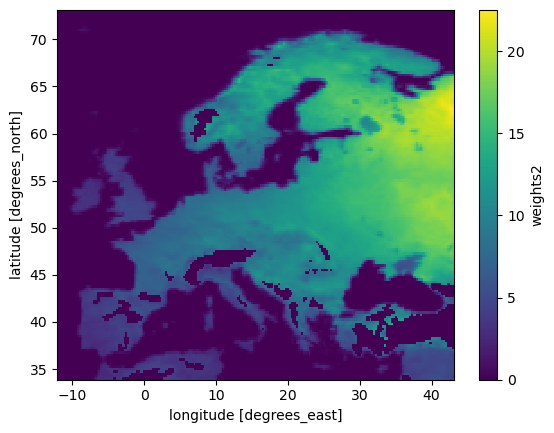

In [71]:
weights2.plot()

In [72]:
explvar_NE = (NE_corr**2).sel(longitude=slice(4,42), latitude=slice(72,59)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_WCE = (WCE_corr**2).sel(longitude=slice(-11,19), latitude=slice(59,47)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_EE = (EE_corr**2).sel(longitude=slice(19,42), latitude=slice(59,47)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_SWE = (SWE_corr**2).sel(longitude=slice(-10,10), latitude=slice(47,36)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_SEE = (SEE_corr**2).sel(longitude=slice(10,30), latitude=slice(47,35)).weighted(weights2).mean(dim=['longitude', 'latitude'])

In [75]:
print(explvar_NE.values)
print(explvar_WCE.values)
print(explvar_EE.values)
print(explvar_SWE.values)
print(explvar_SEE.values)

0.7426624162925209
0.765939544916701
0.795096151490847
0.7701501314153947
0.7402433203195865


In [76]:
corrmean_NE = NE_corr.sel(longitude=slice(4,42), latitude=slice(72,59)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_WCE = WCE_corr.sel(longitude=slice(-11,19), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_EE = EE_corr.sel(longitude=slice(19,42), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_SWE = SWE_corr.sel(longitude=slice(-10,10), latitude=slice(47,36)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_SEE = SEE_corr.sel(longitude=slice(10,30), latitude=slice(47,35)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [77]:
print(corrmean_NE.values)
print(corrmean_WCE.values)
print(corrmean_EE.values)
print(corrmean_SWE.values)
print(corrmean_SEE.values)

0.8480489901482345
0.8501816465283651
0.8832304941145123
0.8648926515579466
0.8247224795575477


In [80]:
NE_corr.to_netcdf('temp_corr_NE.nc')
WCE_corr.to_netcdf('temp_corr_WCE.nc')
EE_corr.to_netcdf('temp_corr_EE.nc')
SWE_corr.to_netcdf('temp_corr_SWE.nc')
SEE_corr.to_netcdf('temp_corr_SEE.nc')